In [34]:
import time
import pubchempy as pcp
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.ensemble import (
    BaggingRegressor,
    GradientBoostingRegressor,
    IsolationForest,
    RandomForestRegressor,
    StackingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree

RANDOM_STATE = 100626

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }

def show_metrics(name, y_true, y_pred):
    values = regression_metrics(y_true, y_pred)
    print(name)
    print(f"  RMSE: {values['RMSE']:.3f}")
    print(f"  MAE:  {values['MAE']:.3f}")
    print(f"  R²:   {values['R2']:.3f}")
    return values


1. read the training 

antimicrobial_train_80pct.csv

and feature-only 

antimicrobial_test_X_20pct.csv

2. exclude IDs, SMILES, and assay metadata from the predictive feature matrix;
3. detect and handle the pseudo-NA values;
4. fit and compare at least 3 dofferent tree-based models (y=target_log10);
5. generate predictions for every row in the feature-only test table - your goal is achieve 22 MAPE, you can use any model we discussed(no deep learning) and any preprocessing you like;
6. submit predictions keyed by molecule_chembl_id, and just orally defend and explain your notebook.

In [79]:
df = pd.read_csv("antimicrobial_train_80pct.csv")

In [80]:
df

,activity_id,molecule_chembl_id,pref_name,compound_name,canonical_smiles,standard_type,standard_units,assay_chembl_id,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,...,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,946920,CHEMBL72286,NaN,NaN,O=C(c1ccccc1O)N1CCc2c(n(Cc3ccc(O)cc3)c3ccccc23)C1,MIC,ug.mL-1,CHEMBL677573,13.081525,13.081525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,379615,CHEMBL134905,NaN,NaN,CC(=O)NC[C@H]1CN(c2ccc3c(c2)CCCCN3C=O)C(=O)O1,MIC,ug.mL-1,CHEMBL677421,12.110715,12.110715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,16571259,CHEMBL3798190,NaN,NaN,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21.O=[N...,MIC,ug.mL-1,CHEMBL3801691,14.494909,14.494909,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,141787,CHEMBL320039,NaN,NaN,N[C@H]1CN(c2c(F)cc3c(=O)c(C(=O)O)cn(C4CC4)c3c2...,MIC,ug.mL-1,CHEMBL677359,15.030342,15.030342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,551390,CHEMBL88523,NaN,NaN,O=C(OCC1=CC=C(COC(=O)c2cccnc2)SS1)c1cccnc1,MIC,ug.mL-1,CHEMBL648210,11.880338,11.880338,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8470,1198295,CHEMBL1160682,NaN,NaN,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(Sc3nc(-c4cc...,MIC,ug.mL-1,CHEMBL673662,12.395635,12.395635,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.795880
8471,952203,CHEMBL88982,NaN,NaN,NCCNC(=O)c1cc(-c2c[nH]c3ccc(Br)cc23)nc2ccccc12...,MIC,ug.mL-1,CHEMBL673511,12.647314,12.647314,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.397940
8472,1190294,CHEMBL275692,NaN,NaN,CC(=O)OCC1=C(C(=O)OC(c2ccccc2)c2ccccc2)N2C(=O)...,MIC,ug.mL-1,CHEMBL670512,13.865431,13.865431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.522879
8473,377863,CHEMBL44431,NaN,NaN,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=C(Cl)C...,MIC,ug.mL-1,CHEMBL673753,12.167056,12.167056,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.806180


In [ ]:
df.columns

Index(['activity_id', 'molecule_chembl_id', 'pref_name', 'compound_name',
       'canonical_smiles', 'standard_type', 'standard_units',
       'assay_chembl_id', 'rdkit_MaxAbsEStateIndex', 'rdkit_MaxEStateIndex',
       ...
       'rdkit_fr_sulfonamd', 'rdkit_fr_sulfone', 'rdkit_fr_term_acetylene',
       'rdkit_fr_tetrazole', 'rdkit_fr_thiazole', 'rdkit_fr_thiocyan',
       'rdkit_fr_thiophene', 'rdkit_fr_unbrch_alkane', 'rdkit_fr_urea',
       'target_log10'],
      dtype='str', length=226)

In [40]:
df['standard_type'].value_counts()

standard_type
MIC    8475
Name: count, dtype: int64

In [6]:
substrings = ["_id", "_smiles", "assay"]

cols_to_drop = [
    col for col in df.columns
    if any(s in col for s in substrings)
]

filtered_df = df.drop(columns=cols_to_drop)

In [7]:
filtered_df.columns

Index(['pref_name', 'compound_name', 'standard_type', 'standard_units',
       'rdkit_MaxAbsEStateIndex', 'rdkit_MaxEStateIndex',
       'rdkit_MinAbsEStateIndex', 'rdkit_MinEStateIndex', 'rdkit_qed',
       'rdkit_SPS',
       ...
       'rdkit_fr_sulfonamd', 'rdkit_fr_sulfone', 'rdkit_fr_term_acetylene',
       'rdkit_fr_tetrazole', 'rdkit_fr_thiazole', 'rdkit_fr_thiocyan',
       'rdkit_fr_thiophene', 'rdkit_fr_unbrch_alkane', 'rdkit_fr_urea',
       'target_log10'],
      dtype='str', length=222)

In [78]:
filtered_df['target_log10'].min()

-3.1079053973095196

In [8]:
missing_by_column = filtered_df.isna().sum().sort_values(ascending=False)
missing_by_row = filtered_df.isna().sum(axis=1)

display(missing_by_column.to_frame("missing_count"))
display((missing_by_column / len(filtered_df)).to_frame("missing_fraction"))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))
print("Rows with more than one missing value:", int((missing_by_row > 1).sum()))

,missing_count
pref_name,8150
compound_name,8150
rdkit_BCUT2D_MRHI,425
rdkit_BCUT2D_MWHI,424
rdkit_BCUT2D_MRLOW,423
...,...
rdkit_PEOE_VSA6,141
rdkit_PEOE_VSA11,140
standard_units,0
standard_type,0


,missing_fraction
pref_name,0.961652
compound_name,0.961652
rdkit_BCUT2D_MRHI,0.050147
rdkit_BCUT2D_MWHI,0.050029
rdkit_BCUT2D_MRLOW,0.049912
...,...
rdkit_PEOE_VSA6,0.016637
rdkit_PEOE_VSA11,0.016519
standard_units,0.000000
standard_type,0.000000


Rows with at least one missing value: 8471
Rows with more than one missing value: 8448


In [9]:
filtered_df['pref_name']

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
8470    NaN
8471    NaN
8472    NaN
8473    NaN
8474    NaN
Name: pref_name, Length: 8475, dtype: str

In [12]:
filtered_df.columns

Index(['standard_type', 'standard_units', 'rdkit_MaxAbsEStateIndex',
       'rdkit_MaxEStateIndex', 'rdkit_MinAbsEStateIndex',
       'rdkit_MinEStateIndex', 'rdkit_qed', 'rdkit_SPS', 'rdkit_MolWt',
       'rdkit_HeavyAtomMolWt',
       ...
       'rdkit_fr_sulfonamd', 'rdkit_fr_sulfone', 'rdkit_fr_term_acetylene',
       'rdkit_fr_tetrazole', 'rdkit_fr_thiazole', 'rdkit_fr_thiocyan',
       'rdkit_fr_thiophene', 'rdkit_fr_unbrch_alkane', 'rdkit_fr_urea',
       'target_log10'],
      dtype='str', length=220)

In [10]:
cols_with_too_many_na =['pref_name', 'compound_name']
filtered_df = filtered_df.drop(columns=cols_with_too_many_na)

In [19]:
cat_cols =['standard_type', 'standard_units']
filtered_df = filtered_df.drop(columns=cat_cols)

In [30]:
filtered_df = filtered_df.drop(columns='rdkit_Ipc')

In [17]:
filtered_df.head()

,standard_type,standard_units,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,rdkit_MinAbsEStateIndex,rdkit_MinEStateIndex,rdkit_qed,rdkit_SPS,rdkit_MolWt,rdkit_HeavyAtomMolWt,...,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,MIC,ug.mL-1,13.081525,13.081525,0.011976,-0.152602,0.540794,13.400000,398.462,376.286,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,MIC,ug.mL-1,12.110715,12.110715,0.149552,-0.410956,0.847072,20.208333,331.372,310.204,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,MIC,ug.mL-1,14.494909,14.494909,0.100124,-1.300287,0.169941,13.195122,595.884,576.732,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,MIC,ug.mL-1,15.030342,15.030342,0.011741,-1.321205,0.839431,23.370370,391.830,372.678,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,MIC,ug.mL-1,11.880338,11.880338,0.185165,-0.412243,0.549826,13.384615,386.454,372.342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030


In [31]:
X = filtered_df.drop(columns='target_log10')
y = filtered_df['target_log10']

In [53]:
filtered_df.head()

,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,rdkit_MinAbsEStateIndex,rdkit_MinEStateIndex,rdkit_qed,rdkit_SPS,rdkit_MolWt,rdkit_HeavyAtomMolWt,rdkit_ExactMolWt,rdkit_NumValenceElectrons,...,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,13.081525,13.081525,0.011976,-0.152602,0.540794,13.400000,398.462,376.286,398.163043,150.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,12.110715,12.110715,0.149552,-0.410956,0.847072,20.208333,331.372,310.204,331.153206,128.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,14.494909,14.494909,0.100124,-1.300287,0.169941,13.195122,595.884,576.732,595.086596,216.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,15.030342,15.030342,0.011741,-1.321205,0.839431,23.370370,391.830,372.678,391.109897,142.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,11.880338,11.880338,0.185165,-0.412243,0.549826,13.384615,386.454,372.342,386.039499,132.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030


In [54]:
filtered_df.columns

Index(['rdkit_MaxAbsEStateIndex', 'rdkit_MaxEStateIndex',
       'rdkit_MinAbsEStateIndex', 'rdkit_MinEStateIndex', 'rdkit_qed',
       'rdkit_SPS', 'rdkit_MolWt', 'rdkit_HeavyAtomMolWt', 'rdkit_ExactMolWt',
       'rdkit_NumValenceElectrons',
       ...
       'rdkit_fr_sulfonamd', 'rdkit_fr_sulfone', 'rdkit_fr_term_acetylene',
       'rdkit_fr_tetrazole', 'rdkit_fr_thiazole', 'rdkit_fr_thiocyan',
       'rdkit_fr_thiophene', 'rdkit_fr_unbrch_alkane', 'rdkit_fr_urea',
       'target_log10'],
      dtype='str', length=217)

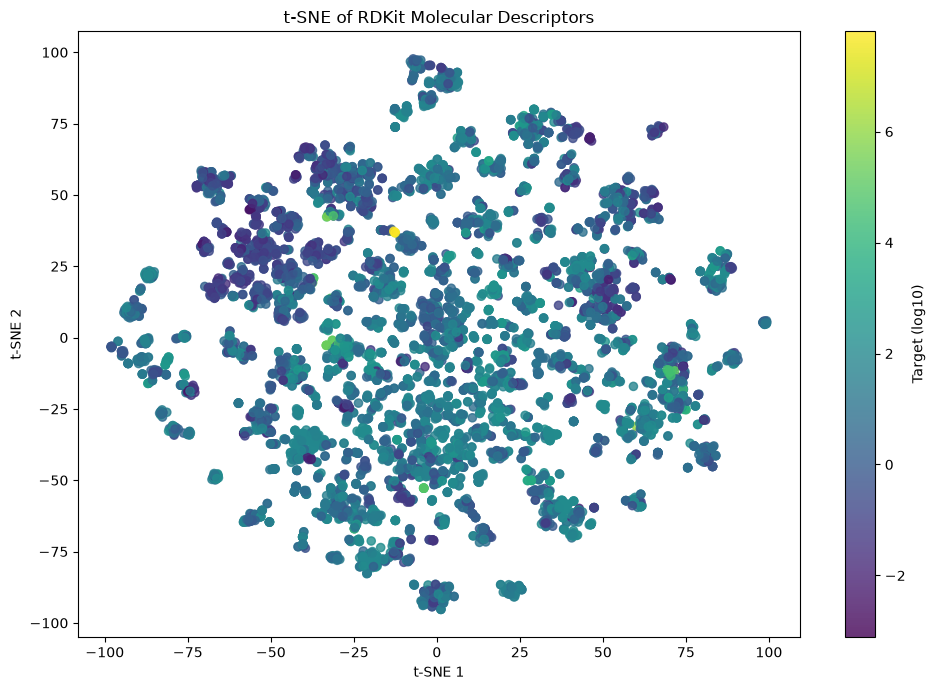

In [55]:
# Handle missing and infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

# Impute and standardize
X_imputed = SimpleImputer(strategy="median").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X_imputed)

# Apply t-SNE directly
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="random",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

# Visualize
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap="viridis",
    s=35,
    alpha=0.8
)

plt.colorbar(scatter, label="Target (log10)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE of RDKit Molecular Descriptors")
plt.tight_layout()
plt.show()

In [61]:
results = {}

In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=12112026)

tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(max_depth=5, min_samples_leaf=8, random_state=RANDOM_STATE))])
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)


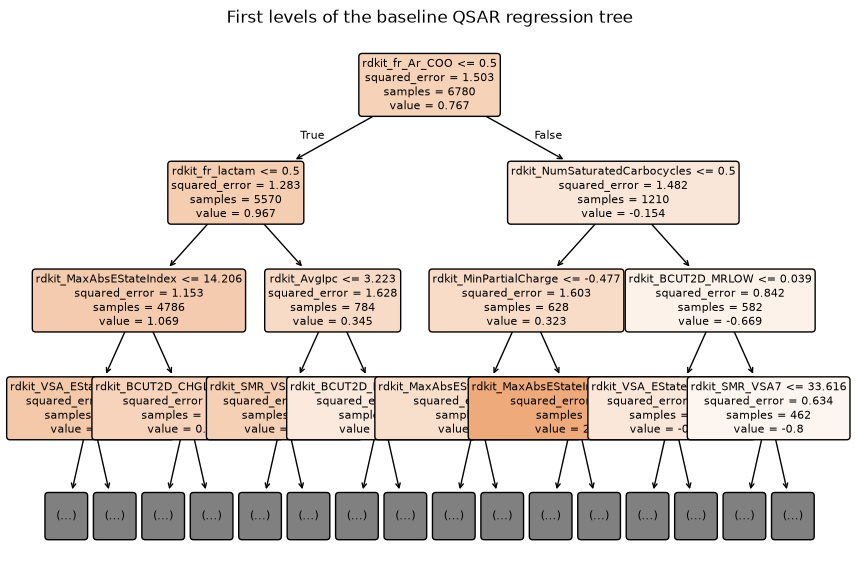

In [70]:
feature_cols = [c for c in filtered_df.columns if c.startswith("rdkit_")]
plt.figure(figsize=(10, 7))
plot_tree(
    tree.named_steps["model"],
    max_depth=3,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=8,)
plt.title("First levels of the baseline QSAR regression tree")
plt.show()

In [62]:
results['baseline_tree'] = regression_metrics(y_test, tree_pred)
pd.Series(regression_metrics(y_test, tree_pred), name="baseline_tree").to_frame()

,baseline_tree
MAE,7.692297e-01
RMSE,9.963797e-01
R2,3.238446e-01
MAPE (%),1.100144e+16


In [41]:
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)

depth_values = [1, 2, 3, 5, 8, 12, None]
depth_rows = []
for depth in depth_values:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(
            max_depth=depth, min_samples_leaf=5, random_state=RANDOM_STATE
        )),
    ])
    model.fit(X_subtrain, y_subtrain)
    depth_rows.append({
        "max_depth": str(depth),
        "train_RMSE": np.sqrt(mean_squared_error(y_subtrain, model.predict(X_subtrain))),
        "validation_RMSE": np.sqrt(mean_squared_error(y_valid, model.predict(X_valid))),
        "train_R2": r2_score(y_subtrain, model.predict(X_subtrain)),
        "validation_R2": r2_score(y_valid, model.predict(X_valid)),
        "train_MAE": mean_absolute_error(y_subtrain, model.predict(X_subtrain)),
        "validation_MAE": mean_absolute_error(y_valid, model.predict(X_valid))
        
    })
depth_results = pd.DataFrame(depth_rows)
depth_results


,max_depth,train_RMSE,validation_RMSE,train_R2,validation_R2,train_MAE,validation_MAE
0,1,1.154500,1.163807,0.115773,0.111302,0.933527,0.940309
1,2,1.104904,1.107717,0.190112,0.194899,0.881195,0.884601
2,3,1.061428,1.081865,0.252594,0.232040,0.847328,0.856019
3,5,0.972075,1.035516,0.373133,0.296431,0.760317,0.795851
4,8,0.836401,0.987743,0.535907,0.359852,0.638980,0.744472
5,12,0.670059,0.987341,0.702147,0.360372,0.474779,0.710402
6,None,0.461535,1.014985,0.858686,0.324054,0.305816,0.712091


In [42]:
depth_long = depth_results.melt(
    id_vars="max_depth",
    value_vars=["train_MAE", "validation_MAE"],
    var_name="split",
    value_name="MAE",
)
depth_fig = px.line(
    depth_long, x="max_depth", y="MAE", color="split", markers=True,
    title="Tree error versus max_depth",
    labels={"MAE": "MAE (lower is better)"},
)
depth_fig.show()

depth_r2_long = depth_results.melt(
    id_vars="max_depth",
    value_vars=["train_R2", "validation_R2"],
    var_name="split",
    value_name="R2",
)
depth_r2_fig = px.line(
    depth_r2_long, x="max_depth", y="R2", color="split", markers=True,
    title="Tree fit versus max_depth",
    labels={"R2": "R² (higher is better)"},
)
depth_r2_fig.show()


In [63]:
imputer_train = SimpleImputer(strategy="median")
X_train_imp = imputer_train.fit_transform(X_train)
X_test_imp = imputer_train.transform(X_test)
rf_model = RandomForestRegressor(
    n_estimators=250,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_model.fit(X_train_imp, y_train)
rf_pred = rf_model.predict(X_test_imp)
results['Random forest'] = regression_metrics(y_test, rf_pred)
show_metrics("Random Forest", y_test, rf_pred)

Random Forest
  RMSE: 0.758
  MAE:  0.563
  R²:   0.608


{'MAE': 0.5633550241312484,
 'RMSE': 0.7583861439249309,
 'R2': 0.6082783836214668,
 'MAPE (%)': 8116405493868092.0}

In [65]:
gb_model = GradientBoostingRegressor(
    n_estimators=250,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    random_state=RANDOM_STATE)

    
gb_model.fit(X_train_imp, y_train)
gb_pred = gb_model.predict(X_test_imp)
results['Gradient Boosting'] = regression_metrics(y_test, gb_model.predict(X_test_imp))
show_metrics("Gradient Boosting", y_test, gb_pred)

Gradient Boosting
  RMSE: 0.940
  MAE:  0.733
  R²:   0.398


{'MAE': 0.7327710493682764,
 'RMSE': 0.9403982239564311,
 'R2': 0.39768960420599264,
 'MAPE (%)': 1.008315172925311e+16}

In [64]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=-1)
xgb_model.fit(X_train_imp, y_train)
results['XGBoost'] = regression_metrics(y_test, xgb_model.predict(X_test_imp))
show_metrics("XGBoost", y_test, xgb_model.predict(X_test_imp))

XGBoost
  RMSE: 0.796
  MAE:  0.609
  R²:   0.568


{'MAE': 0.6088075413207822,
 'RMSE': 0.7961949330435423,
 'R2': 0.5682467877001088,
 'MAPE (%)': 9228355426375386.0}

In [66]:
results

{'baseline_tree': {'MAE': 0.7692297040699938,
  'RMSE': 0.9963797078592057,
  'R2': 0.32384462156392757,
  'MAPE (%)': 1.1001440758956256e+16},
 'Random forest': {'MAE': 0.5633550241312484,
  'RMSE': 0.7583861439249309,
  'R2': 0.6082783836214668,
  'MAPE (%)': 8116405493868092.0},
 'XGBoost': {'MAE': 0.6088075413207822,
  'RMSE': 0.7961949330435423,
  'R2': 0.5682467877001088,
  'MAPE (%)': 9228355426375386.0},
 'Gradient Boosting': {'MAE': 0.7327710493682764,
  'RMSE': 0.9403982239564311,
  'R2': 0.39768960420599264,
  'MAPE (%)': 1.008315172925311e+16}}

In [71]:
test = pd.read_csv('antimicrobial_test_X_20pct.csv')

In [72]:
test.columns

Index(['activity_id', 'molecule_chembl_id', 'pref_name', 'compound_name',
       'canonical_smiles', 'standard_type', 'standard_units',
       'assay_chembl_id', 'rdkit_MaxAbsEStateIndex', 'rdkit_MaxEStateIndex',
       ...
       'rdkit_fr_sulfide', 'rdkit_fr_sulfonamd', 'rdkit_fr_sulfone',
       'rdkit_fr_term_acetylene', 'rdkit_fr_tetrazole', 'rdkit_fr_thiazole',
       'rdkit_fr_thiocyan', 'rdkit_fr_thiophene', 'rdkit_fr_unbrch_alkane',
       'rdkit_fr_urea'],
      dtype='str', length=225)

In [74]:
# Зберігаємо ID молекул
test_ids = test["molecule_chembl_id"].copy()

# Вибираємо тільки фічі, на яких навчалася модель
X_final_test = test[feature_cols].copy()

# Перевіряємо відповідність фіч
assert list(X_final_test.columns) == list(feature_cols)

In [75]:
test_predictions = rf_model.predict(X_final_test)

/Users/elizavetafisun/Documents/ML_Bio/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


In [76]:
submission = pd.DataFrame({
    "molecule_chembl_id": test_ids.to_numpy(),
    "target_log10": test_predictions
})

submission.head()

,molecule_chembl_id,target_log10
0,CHEMBL121649,0.703717
1,CHEMBL68208,0.928595
2,CHEMBL134718,0.537589
3,CHEMBL346824,1.435396
4,CHEMBL129494,1.767171


In [77]:
submission.to_csv("submission.csv", index=False)